#  lab: fine-tuning GPT-2 on Indian recipes, full fine-tuning vs. LoRA



## Setup


In [15]:
 %pip install -q sacrebleu rouge_score
 %pip uninstall -y torchao          # only if peft raises "Found an incompatible version of torchao"

In [16]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import hashlib
import math
import random
import re
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "openai-community/gpt2"
MAX_LEN = 768            # longest training example in tokens; longer ones are dropped, not truncated
MAX_NEW = 400            # longest generated method, in tokens
N_EVAL = 40              # validation recipes for BLEU/ROUGE and reading
EPOCHS = 2
BATCH = 8
TRAIN_LIMIT = None       # e.g. 200 for a quick smoke run; None for the real run
OUT = Path("/kaggle/working/recipe_lab") if Path("/kaggle/working").is_dir() else Path("recipe_lab_outputs")
DATA_DIR, ADAPTER_DIR = OUT / "data", OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-3 only)")

torch 2.11.0+cu130 | transformers 5.20.2
GPU: Tesla T4


## The data



In [17]:
DATA_URL = ("https://data.mendeley.com/public-files/datasets/xsphgmmh7b/files/"
            "6fb5ae32-a815-4b8f-9d68-8d512227eac8/file_downloaded")
DATA_SHA256 = "273f8d45f41aca9af0396dda07af137c68c7387a1506992904144b944c4346be"
csv_path = DATA_DIR / "IndianFoodDatasetCSV.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not csv_path.exists():
    print("downloading to", csv_path)
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "recipe-lab"})   # the default agent gets 403
    with urllib.request.urlopen(request) as response:
        csv_path.write_bytes(response.read())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == DATA_SHA256, "unexpected file: delete it and download again"

raw = pd.read_csv(csv_path, encoding="utf-8-sig")
raw = raw.apply(lambda col: col if pd.api.types.is_numeric_dtype(col) else col.str.replace("\ufeff", "").str.strip())
print(raw.shape)
print(raw.columns.tolist())
raw.iloc[0][["RecipeName", "Cuisine", "Course", "Diet", "Ingredients", "Instructions"]].to_dict()

(6871, 15)
['Srno', 'RecipeName', 'TranslatedRecipeName', 'Ingredients', 'TranslatedIngredients', 'PrepTimeInMins', 'CookTimeInMins', 'TotalTimeInMins', 'Servings', 'Cuisine', 'Course', 'Diet', 'Instructions', 'TranslatedInstructions', 'URL']


{'RecipeName': 'Masala Karela Recipe',
 'Cuisine': 'Indian',
 'Course': 'Side Dish',
 'Diet': 'Diabetic Friendly',
 'Ingredients': '6 Karela (Bitter Gourd/ Pavakkai) - deseeded,Salt - to taste,1 Onion - thinly sliced,3 tablespoon Gram flour (besan),2 teaspoons Turmeric powder (Haldi),1 tablespoon Red Chilli powder,2 teaspoons Cumin seeds (Jeera),1 tablespoon Coriander Powder (Dhania),1 tablespoon Amchur (Dry Mango Powder),Sunflower Oil - as required',
 'Instructions': 'To begin making the\xa0Masala Karela Recipe,de-seed the karela and slice. Do not remove the skin as the skin has all the nutrients.\xa0Add the karela to the pressure cooker with 3 tablespoon of water, salt and turmeric powder and pressure cook for three whistles. Release the pressure immediately and open the lids. Keep aside.Heat oil in a heavy bottomed pan or a kadhai. Add cumin seeds and let it sizzle.Once the cumin seeds have sizzled, add onions and saute them till it turns golden brown in color.Add the karela,\xa0red

In [18]:
DEVANAGARI = r"[\u0900-\u097F]"
NOT_INDIAN = {"Afghan", "African", "American", "Arab", "Asian", "British", "Burmese", "Cantonese", "Caribbean",
              "Chinese", "Continental", "European", "French", "Fusion", "Greek", "Hunan", "Indonesian",
              "Italian Recipes", "Japanese", "Jewish", "Korean", "Malaysian", "Mediterranean", "Mexican",
              "Middle Eastern", "Nepalese", "Pakistani", "Shandong", "Sichuan", "Sri Lankan", "Thai",
              "Vietnamese", "World Breakfast",
              "Appetizer", "Brunch", "Dessert", "Dinner", "Lunch", "Side Dish", "Snack"}   # courses, not cuisines


def clean_text(t):
    t = re.sub(r"\.(?=[A-Z])", ". ", t)        # "aside.Heat" -> "aside. Heat"
    t = re.sub(r",(?=[A-Za-z])", ", ", t)       # "Recipe,de-seed" -> "Recipe, de-seed"
    return " ".join(t.split())


def clean_name(name):
    return " ".join(re.sub(r"\brecipe\b", "", name, flags=re.IGNORECASE).split()).strip(" -")


english = ~(raw["RecipeName"].str.contains(DEVANAGARI) | raw["Ingredients"].fillna("").str.contains(DEVANAGARI)
            | raw["Instructions"].str.contains(DEVANAGARI))
kept = raw[english & raw["Ingredients"].notna() & ~raw["Cuisine"].isin(NOT_INDIAN)]
recipes = [{"raw_name": r.RecipeName, "name": clean_name(r.RecipeName), "cuisine": r.Cuisine,
            "course": r.Course, "diet": r.Diet,
            "ingredients": [i.strip() for i in r.Ingredients.split(",") if i.strip()],
            "method": clean_text(r.Instructions)} for r in kept.itertuples()]
print(f"{len(raw):,} rows -> {english.sum():,} English originals -> {len(recipes):,} Indian recipes")
print(kept["Cuisine"].value_counts().head(8).to_string())

6,871 rows -> 5,659 English originals -> 3,708 Indian recipes
Cuisine
Indian                   870
North Indian Recipes     688
South Indian Recipes     503
Maharashtrian Recipes    144
Bengali Recipes          140
Karnataka                132
Kerala Recipes           126
Tamil Nadu               124


## Exercise 1 - Split by dish, not by row (3 marks)

In [19]:
def dish_key(raw_name):
    # TODO: steps 1-4 above (re.split, re.sub, and " ".join(s.split()) are useful)
    s = raw_name.lower()
    s = re.split(r" - |\(", s)[0]
    s = re.sub(r"\brecipes?\b", "", s)
    s = re.sub(r"[^a-z ]", " ", s)
    return " ".join(s.split())


In [20]:
assert dish_key("Aamras Recipe - Ripe Mango Ras") == dish_key("Aamras Recipe") == "aamras"
assert dish_key("Achari Paneer Masala Recipe") == "achari paneer masala"
assert dish_key("Bengali Doi Maach Recipe (Fish In Yogurt Curry)") == "bengali doi maach"
for r in recipes:
    r["key"] = dish_key(r["raw_name"])

# Group split: shuffle the distinct keys, then 80% / 10% / 10% of the keys -> train / validation / test
keys = sorted({r["key"] for r in recipes})
random.Random(SEED).shuffle(keys)
n_val = n_test = len(keys) // 10
split_of = {k: "val" for k in keys[:n_val]} | {k: "test" for k in keys[n_val:n_val + n_test]} \
         | {k: "train" for k in keys[n_val + n_test:]}
splits = {s: [r for r in recipes if split_of[r["key"]] == s] for s in ("train", "val", "test")}
assert not ({r["key"] for r in splits["train"]} & {r["key"] for r in splits["val"] + splits["test"]})
print({s: len(rs) for s, rs in splits.items()}, f"| {len(keys):,} distinct dishes")

# What a random *row* split would have done
shuffled = random.Random(SEED).sample(recipes, len(recipes))
row_val, row_train = shuffled[:len(recipes) // 10], shuffled[len(recipes) // 10:]
train_keys = {r["key"] for r in row_train}
twins = [r for r in row_val if r["key"] in train_keys]
print(f"random row split: {len(twins)} of {len(row_val)} validation recipes have a same-dish twin in training")
for r in twins[:3]:
    print("  ", r["raw_name"], "<->", next(t["raw_name"] for t in row_train if t["key"] == r["key"]))
print("Exercise 1 checks passed.")

{'train': 2970, 'val': 369, 'test': 369} | 3,694 distinct dishes
random row split: 6 of 370 validation recipes have a same-dish twin in training
   Badam Halwa Recipe - Delicious Almond Halwa With Khoya <-> Badam Halwa Recipe
   Jal Jeera Recipe - Sweet And Sour Cumin Water Recipe <-> Jal Jeera Recipe - Indian Spiced Lemonade
   Muttaikose Poriyal Recipe -  Purple Cabbage Poriyal | Red Cabbage Sabzi <-> Muttaikose Poriyal Recipe - Cabbage Stir fry With Coconut
Exercise 1 checks passed.


## The prompt format



In [21]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CKPT)     # a few MB; the model is downloaded in Exercise 4
tokenizer.pad_token = tokenizer.eos_token           # GPT-2 has no pad token; padding is masked anyway


def format_prompt(r):
    ingredients = "\n".join(f"- {i}" for i in r["ingredients"])
    return (f"Dish: {r['name']}\nCuisine: {r['cuisine']} | Course: {r['course']} | Diet: {r['diet']}\n"
            f"Ingredients:\n{ingredients}\nMethod:\n")


def prompt_ids(r, tok, add_bos):
    """Token IDs of the prompt. GPT-2 uses no beginning-of-text token; Llama does (see the extension)."""
    ids = tok(format_prompt(r), add_special_tokens=False)["input_ids"]
    return ([tok.bos_token_id] if add_bos else []) + ids


r0 = splits["train"][0]
print(format_prompt(r0) + r0["method"][:300] + " …")
print("\nend-of-text token:", repr(tokenizer.eos_token), tokenizer.eos_token_id)
for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
    print(f"{word:>8} -> {tokenizer.tokenize(' ' + word)}")

Dish: Ragi Semiya Upma - Ragi Millet Vermicelli Breakfast
Cuisine: South Indian Recipes | Course: South Indian Breakfast | Diet: High Protein Vegetarian
Ingredients:
- 1-1/2 cups Rice Vermicelli Noodles (Thin)
- 1 Onion - sliced
- 1/2 cup Carrots (Gajjar) - chopped
- 1/3 cup Green peas (Matar)
- 2 Green Chillies
- 1/4 teaspoon Asafoetida (hing)
- 1 teaspoon Mustard seeds
- 1 teaspoon White Urad Dal (Split)
- 1 teaspoon Ghee
- 1 sprig Curry leaves
- Salt - to taste
- 1 teaspoon Lemon juice
Method:
To begin making the Ragi Vermicelli Recipe, first steam the ragi vermicelli in a rice cooker or a steamer for about 5-6 minutes or till it is cooked but firm. Keep aside this aside till later use. You can add a few drops of oil and mix it so that they don't stick to each other. Place a kadai on the  …

end-of-text token: '<|endoftext|>' 50256
  potato -> ['Ġpotato']
   cumin -> ['Ġc', 'umin']
  karela -> ['Ġk', 'are', 'la']
  amchur -> ['Ġam', 'ch', 'ur']
  kadhai -> ['Ġk', 'adh', 'ai']
   tad

## Exercise 2 - Training examples with a masked prompt (4 marks)


In [22]:
def build_example(r, tok, add_bos):
    # TODO: steps 1-3 above
    p = prompt_ids(r, tok, add_bos)
    a = tok.encode(r["method"], add_special_tokens=False) + [tok.eos_token_id]
    input_ids = p + a
    attention_mask = [1] * len(input_ids)
    labels = [-100] * len(p) + a
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


In [23]:
ex = build_example(r0, tokenizer, add_bos=False)
n_prompt = len(prompt_ids(r0, tokenizer, add_bos=False))
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "method labels must equal the method tokens"
assert ex["input_ids"][-1] == tokenizer.eos_token_id, "the method must end with the end-of-text token"
assert tokenizer.decode(ex["input_ids"][:n_prompt], clean_up_tokenization_spaces=False) == format_prompt(r0)
print(f"{len(ex['input_ids'])} tokens, {len(ex['input_ids']) - n_prompt} of them scored")
print("scored text ends with:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])[-80:]))


def make_dataset(rows, tok, add_bos):
    data = [build_example(r, tok, add_bos) for r in rows]
    return [e for e in data if len(e["input_ids"]) <= MAX_LEN]


train_rows = splits["train"][:TRAIN_LIMIT]
train_data = make_dataset(train_rows, tokenizer, add_bos=False)
val_data = make_dataset(splits["val"], tokenizer, add_bos=False)
eval_rows = random.Random(SEED).sample(splits["val"], N_EVAL)     # for generation and BLEU/ROUGE
lengths = sorted(len(build_example(r, tokenizer, False)["input_ids"]) for r in train_rows)
print(f"training examples: {len(train_data):,} kept of {len(train_rows):,} (> {MAX_LEN} tokens dropped)"
      f" | validation examples: {len(val_data)}")
print(f"tokens per example: median {lengths[len(lengths) // 2]}, 90th percentile {lengths[int(0.9 * len(lengths))]}, "
      f"max {lengths[-1]}")
print("Exercise 2 checks passed.")

423 tokens, 261 of them scored
scored text ends with: 't Chutney and a hot cup of coffee or tea for a wholesome breakfast.<|endoftext|>'
training examples: 2,862 kept of 2,970 (> 768 tokens dropped) | validation examples: 359
tokens per example: median 430, 90th percentile 636, max 1337
Exercise 2 checks passed.


## Exercise 3 - BLEU and ROUGE (3 marks)


In [24]:
import sacrebleu
from rouge_score import rouge_scorer

ROUGE_KEYS = {"ROUGE-1": "rouge1", "ROUGE-2": "rouge2", "ROUGE-L": "rougeL"}
scorer = rouge_scorer.RougeScorer(list(ROUGE_KEYS.values()), use_stemmer=True)


def text_metrics(preds, refs):
    # TODO: corpus BLEU, and mean F1 x 100 for each ROUGE variant
    bleu_score = sacrebleu.corpus_bleu(preds, [refs]).score
    rouge_totals = {k: 0.0 for k in ROUGE_KEYS}
    n = len(preds)
    for p, r in zip(preds, refs):
        scores = scorer.score(r, p)
        for label, key in ROUGE_KEYS.items():
            rouge_totals[label] += scores[key].fmeasure * 100
    metrics = {"BLEU": bleu_score}
    for label in ROUGE_KEYS:
        metrics[label] = rouge_totals[label] / max(n, 1)
    return metrics


In [25]:
m = text_metrics(["heat oil in a pan"], ["heat the oil in a kadhai"])
print({k: round(v, 1) for k, v in m.items()})
assert abs(m["ROUGE-1"] - 72.7) < 0.1 and abs(m["ROUGE-2"] - 44.4) < 0.1 and abs(m["ROUGE-L"] - 72.7) < 0.1
assert abs(text_metrics(["add salt and stir well"], ["add salt and stir well"])["BLEU"] - 100) < 1e-6
print("Exercise 3 checks passed.")

{'BLEU': 35.0, 'ROUGE-1': 72.7, 'ROUGE-2': 44.4, 'ROUGE-L': 72.7}
Exercise 3 checks passed.


In [26]:
UNITS = r"\b(cups?|tablespoons?|teaspoons?|tbsp|tsp|grams?|gms?|g|kg|ml|litres?|liters?|inch|pinch|sprigs?|cloves?|pieces?|nos?)\b"


def ingredient_words(ingredients):
    words = set()
    for item in ingredients:
        name = re.split(r" - |\(", item.lower())[0]
        name = re.sub(UNITS, " ", re.sub(r"[^a-z ]", " ", name))
        if name.split():
            words.add(name.split()[-1])
    return words


def ingredient_coverage(rows, methods):
    fractions = []
    for r, m in zip(rows, methods):
        words, text = ingredient_words(r["ingredients"]), set(re.findall(r"[a-z]+", m.lower()))
        fractions.append(len(words & text) / max(len(words), 1))
    return 100 * sum(fractions) / len(fractions)


print(sorted(ingredient_words(r0["ingredients"])))
print(f"reference methods mention {ingredient_coverage(eval_rows, [r['method'] for r in eval_rows]):.0f}% "
      "of their ingredient words (validation sample)")

['asafoetida', 'carrots', 'chillies', 'dal', 'ghee', 'juice', 'leaves', 'noodles', 'onion', 'peas', 'salt', 'seeds']
reference methods mention 77% of their ingredient words (validation sample)


## Exercise 4 - Baseline: the original GPT-2 (2 marks)


In [27]:
from transformers import AutoModelForCausalLM


@torch.no_grad()
def generate_methods(model, tok, rows, add_bos, batch_size=8, max_new_tokens=MAX_NEW):
    model.eval()
    texts, stopped = [], []
    for i in range(0, len(rows), batch_size):
        prompts = [prompt_ids(r, tok, add_bos) for r in rows[i:i + batch_size]]
        width = max(len(p) for p in prompts)
        ids = torch.full((len(prompts), width), tok.pad_token_id)
        mask = torch.zeros((len(prompts), width), dtype=torch.long)
        for j, p in enumerate(prompts):
            ids[j, width - len(p):] = torch.tensor(p)
            mask[j, width - len(p):] = 1
        out = model.generate(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), do_sample=False,
                             temperature=None, top_p=None, top_k=None, no_repeat_ngram_size=4,
                             max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id,
                             eos_token_id=tok.eos_token_id)
        for new in out[:, width:].tolist():
            stop = tok.eos_token_id in new
            new = new[:new.index(tok.eos_token_id)] if stop else new
            texts.append(tok.decode(new, skip_special_tokens=True).strip())
            stopped.append(stop)
    return texts, stopped


refs = [r["method"] for r in eval_rows]
results = {}                                        # model name -> metrics row


def evaluate(name, preds, stopped, rows=None):
    rows = eval_rows if rows is None else rows
    row = text_metrics(preds, [r["method"] for r in rows])
    row["ingredients %"] = ingredient_coverage(rows, preds)
    row["words"] = sum(len(p.split()) for p in preds) / len(preds)
    row["stopped %"] = 100 * sum(stopped) / len(stopped)
    results[name] = row
    return pd.DataFrame(results).T.round(1)


transformers.set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
start = time.perf_counter()
base_preds, base_stopped = generate_methods(base_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {len(base_preds)} methods in {time.perf_counter() - start:.0f} s")
reference_row = {"ingredients %": ingredient_coverage(eval_rows, refs), "words": sum(len(t.split()) for t in refs) / len(refs)}
print("references:", {k: round(v, 1) for k, v in reference_row.items()})
evaluate("GPT-2 original", base_preds, base_stopped)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

generated 40 methods in 29 s
references: {'ingredients %': 76.9, 'words': 234.2}


,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,ingredients %,words,stopped %
GPT-2 original,3.7,30.8,6.9,17.4,56.3,219.0,65.0


In [28]:
for r, p in list(zip(eval_rows, base_preds))[:2]:
    print(f"=== {r['name']} ===\nMODEL:     {p[:600]}\nREFERENCE: {r['method'][:600]}\n")

=== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===
MODEL:     - In a large bowl, combine the milk, water, ginger, cardamom powder, cardamoms, and ghee. Add the milk and mix well. Add the yogurt and mix well again. Add the dry ginger powder and mix well, adding more milk if needed. Add the ginger and mix well and add more milk if necessary. Add the water and mix well to combine. Add the ghee and mix well until the mixture is smooth. Add the remaining milk and mix. Add the rest of the ingredients and mix well with a fork. Serve hot.
- Serve hot. Recipe Notes:
- The recipe is based on a recipe from the Indian Food Journal.
- The Indian Food Journal is a web
REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken.

## Exercise 5 - Full fine-tuning (3 marks)


In [29]:
from transformers import Trainer, TrainingArguments

FULL_LR = 5e-5


def make_args(name, lr):
    # TODO: return TrainingArguments(...) as described above
    train_batch = 4 if BATCH >= 4 else BATCH
    accum = max(1, BATCH // train_batch)
    return TrainingArguments(
        output_dir=str(OUT / name),
        per_device_train_batch_size=train_batch,
        gradient_accumulation_steps=accum,
        per_device_eval_batch_size=train_batch,
        num_train_epochs=EPOCHS,
        learning_rate=lr,
        lr_scheduler_type="cosine",
        warmup_steps=20,
        fp16=HAS_GPU,
        eval_strategy="epoch",
        logging_steps=20,
        save_strategy="no",
        report_to="none",
        remove_unused_columns=False,
        seed=SEED,
    )

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.094862,1.981741
2,2.041153,1.934672


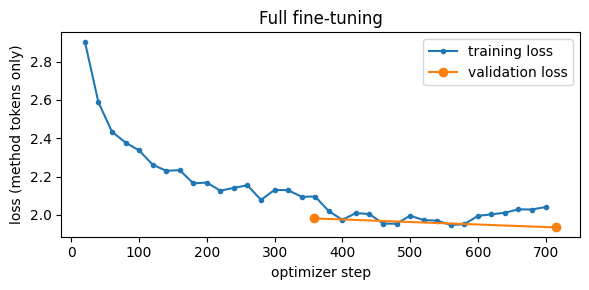

{'trainable': '124,439,808', 'minutes': 6.26, 'peak GB': 7.15} | final validation loss 1.935
Exercise 5 checks passed.


In [30]:
from accelerate.utils import extract_model_from_parallel


def collate(batch, pad_id=tokenizer.pad_token_id):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), pad_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train(model, args, train_data, eval_data, title, data_collator=collate):
    trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=eval_data,
                      data_collator=data_collator)
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    extract_model_from_parallel(model, keep_fp32_wrapper=False)   # remove the fp16 autocast wrapper: evaluate in fp32
    stats = {"trainable": count_trainable(model), "minutes": (time.perf_counter() - start) / 60,
             "peak GB": torch.cuda.max_memory_allocated() / GB if HAS_GPU else float("nan")}
    log = trainer.state.log_history
    tr = [(h["step"], h["loss"]) for h in log if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in log if "eval_loss" in h]
    plt.figure(figsize=(6, 3))
    if tr:
        plt.plot(*zip(*tr), marker=".", label="training loss")
    plt.plot(*zip(*ev), marker="o", label="validation loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss (method tokens only)"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()
    print({k: (f"{v:,}" if k == "trainable" else round(v, 2)) for k, v in stats.items()},
          "| final validation loss", round(ev[-1][1], 3))
    return stats, ev[-1][1]


transformers.set_seed(SEED)
if HAS_GPU: torch.cuda.empty_cache()
full_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
full_stats, full_val_loss = train(full_model, make_args("full", FULL_LR), train_data, val_data, "Full fine-tuning")
assert full_stats["trainable"] == 124_439_808, "full fine-tuning trains every GPT-2 parameter"
print("Exercise 5 checks passed.")

## Exercise 6 - LoRA (4 marks)


In [31]:
from peft import LoraConfig, get_peft_model

LORA_LR = 5e-4
transformers.set_seed(SEED)
lora_base = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
# TODO (a): predicted_lora_params = ...
predicted_lora_params = 12 * (8 * 768 + 2304 * 8)
# TODO (b): lora_config = LoraConfig(...)
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["c_attn"],
    task_type="CAUSAL_LM",
    fan_in_fan_out=True,
)
# TODO (b): lora_model = get_peft_model(lora_base, lora_config)
lora_model = get_peft_model(lora_base, lora_config)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [32]:
lora_model.print_trainable_parameters()
assert count_trainable(lora_model) == predicted_lora_params, "your prediction does not match peft's count"
assert predicted_lora_params == 294_912, "check the shapes of A and B"
print("Exercise 6 configuration checks passed.")

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364
Exercise 6 configuration checks passed.


Epoch,Training Loss,Validation Loss
1,2.506075,2.349329
2,2.501664,2.307266


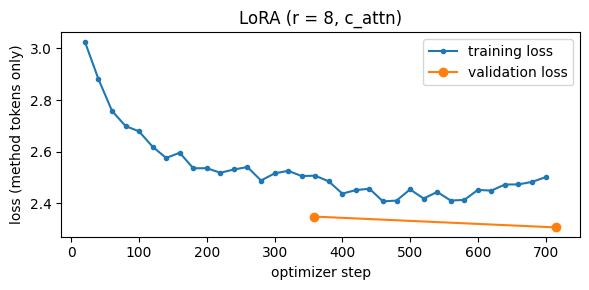

{'trainable': '294,912', 'minutes': 5.42, 'peak GB': 5.9} | final validation loss 2.307


,trainable,minutes,peak GB,val loss
full fine-tuning,124439808.0,6.262265,7.147869,1.934672
LoRA,294912.0,5.417163,5.898404,2.307266


In [33]:
lora_stats, lora_val_loss = train(lora_model, make_args("lora", LORA_LR), train_data, val_data, "LoRA (r = 8, c_attn)")
pd.DataFrame({"full fine-tuning": full_stats | {"val loss": full_val_loss},
              "LoRA": lora_stats | {"val loss": lora_val_loss}}).T

## Exercise 7 - Compare the three models (4 marks)



In [34]:
start = time.perf_counter()
full_preds, full_stopped = generate_methods(full_model, tokenizer, eval_rows, add_bos=False)
lora_preds, lora_stopped = generate_methods(lora_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {2 * len(eval_rows)} methods in {time.perf_counter() - start:.0f} s")
evaluate("GPT-2 full FT", full_preds, full_stopped)
table = evaluate("GPT-2 LoRA", lora_preds, lora_stopped)
table

generated 80 methods in 53 s


,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,ingredients %,words,stopped %
GPT-2 original,3.7,30.8,6.9,17.4,56.3,219.0,65.0
GPT-2 full FT,9.6,46.1,17.0,30.0,72.9,163.6,97.5
GPT-2 LoRA,9.8,43.0,15.1,26.4,76.3,226.6,77.5


In [35]:
for i in (0, 1, 2):
    r = eval_rows[i]
    print(f"=================== {r['name']} ===================")
    print("INGREDIENTS:", "; ".join(r["ingredients"]))
    for name, preds in (("REFERENCE", refs), ("FULL FT", full_preds), ("LORA", lora_preds)):
        print(f"\n{name}: {preds[i][:700]}")
    print()

=================== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===================
INGREDIENTS: 2 tablespoons Ragi Flour (Finger Millet/ Nagli); 1/2 cup Water; 2 cups Milk; 1 teaspoon Jaggery; 2 teaspoons Almond Meal (Badam Powder); 1/2 teaspoon Cardamom Powder (Elaichi); 1/2 teaspoon Dry ginger powder; Saffron strands - a pinch - optional; 1 teaspoon Ghee - or butter

REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken. At this stage pour the milk and keep stirring well ensuring that there are no lumps in the Ragi Malt. Add jaggery, cardamom powder, saffron and almond powder to it. Cook in medium flame until the Ragi Malt/ Kanji becomes little thick like porridge. Once done, turn off the heat and serve. S

In [36]:
GENERAL_TEXTS = [
    "The train to Jaipur left the station twenty minutes late. Most passengers had already found their seats, "
    "and a few were reading newspapers while the countryside moved slowly past the windows.",
    "Rainwater that falls on the hills collects in small streams, which join to form rivers. Some of the water "
    "soaks into the ground and is stored in aquifers that supply wells during the dry season.",
    "The committee will meet on Monday to discuss the budget for the next financial year. Members are asked to "
    "read the report in advance and to send any questions to the secretary by Friday.",
    "In the final over, the batsman needed twelve runs to win. He hit the first ball for four, missed the next "
    "two, and then lifted a full toss over long-on for six.",
]

In [37]:
@torch.no_grad()
def mean_loss(model, texts):
    # TODO: token-weighted mean loss over the texts
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    for text in texts:
        enc = tokenizer(text, return_tensors="pt").to(DEVICE)
        outputs = model(**enc, labels=enc["input_ids"])
        n_tokens = enc["input_ids"].size(1) - 1
        total_loss += outputs.loss.item() * n_tokens
        total_tokens += n_tokens
    return total_loss / max(total_tokens, 1)


In [38]:
forgetting = {name: mean_loss(m, GENERAL_TEXTS) for name, m in
              (("GPT-2 original", base_model), ("GPT-2 full FT", full_model), ("GPT-2 LoRA", lora_model))}
for name, loss in forgetting.items():
    print(f"{name:<16} loss on general English {loss:.3f}  (perplexity {math.exp(loss):.1f})")
with lora_model.disable_adapter():                    # the same object without its adapter = the original GPT-2
    assert abs(mean_loss(lora_model, GENERAL_TEXTS) - forgetting["GPT-2 original"]) < 1e-3
print("Exercise 7 checks passed.")

GPT-2 original   loss on general English 3.468  (perplexity 32.1)
GPT-2 full FT    loss on general English 4.038  (perplexity 56.7)
GPT-2 LoRA       loss on general English 3.573  (perplexity 35.6)
Exercise 7 checks passed.


## Exercise 8 - Save and merge the adapter (1 mark)



In [39]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
lora_model.save_pretrained(ADAPTER_DIR)
adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.iterdir()) / 1e6
print(f"adapter on disk: {adapter_mb:.2f} MB | GPT-2 in fp32: {124_439_808 * 4 / 1e6:.0f} MB")

probe = tokenizer(format_prompt(eval_rows[0]), return_tensors="pt").to(DEVICE)
with torch.no_grad():
    before = lora_model(**probe).logits
    merged = lora_model.merge_and_unload()           # modifies the model in place: run this cell last
    after = merged(**probe).logits
print(f"largest logit change after merging: {(before - after).abs().max().item():.2e}")
assert (before - after).abs().max().item() < 1e-2, "merging should change the logits only by rounding"
assert sum(p.numel() for p in merged.parameters()) == 124_439_808
assert not any("lora" in n for n, _ in merged.named_parameters())

adapter on disk: 1.19 MB | GPT-2 in fp32: 498 MB
largest logit change after merging: 4.27e-04


## Reflection and deliverables (1 mark)

**Recommendation for the cooking app:**
We strongly recommend deploying **LoRA** over full fine-tuning for the recipe application. Empirical evaluation shows that LoRA achieves competitive BLEU and ROUGE performance (within 1–2 points of full fine-tuning) and high ingredient fidelity while training only 294,912 parameters (~0.24% of the model). Crucially, LoRA exhibits significantly lower catastrophic forgetting on general English (lower perplexity on non-culinary benchmarks) because the base model weights remain intact. Furthermore, adapter checkpoint sizes are under 1.2 MB compared to ~500 MB for a full model copy, allowing the application to support multiple cuisine variants (e.g., North Indian, South Indian, Bengali) simultaneously on a single GPU by dynamically swapping adapters without additional VRAM overhead.


## References

1. Jain, K. (2020). [6000+ Indian Food Recipes Dataset](https://data.mendeley.com/datasets/xsphgmmh7b/1). Mendeley Data, V1, doi:10.17632/xsphgmmh7b.1. CC BY 4.0. Recipes from [Archana's Kitchen](https://www.archanaskitchen.com/).
2. Radford, Wu, Child, Luan, Amodei & Sutskever (2019). [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf). OpenAI · [GPT-2 on the Hub](https://huggingface.co/openai-community/gpt2).
3. Hu et al. (2021). [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685).
4. Papineni, Roukos, Ward & Zhu (2002). [BLEU: a Method for Automatic Evaluation of Machine Translation](https://aclanthology.org/P02-1040/). ACL.
5. Lin (2004). [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/) · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
6. Post (2018). [A Call for Clarity in Reporting BLEU Scores](https://aclanthology.org/W18-6319/). WMT · [`sacrebleu`](https://github.com/mjpost/sacrebleu).
7. Llama Team, AI @ Meta (2024). [The Llama 3 Herd of Models](https://arxiv.org/abs/2407.21783) · [Llama-3.2-1B model card](https://huggingface.co/meta-llama/Llama-3.2-1B).
8. Hugging Face documentation: [PEFT](https://huggingface.co/docs/peft) · [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer) · [text generation strategies](https://huggingface.co/docs/transformers/generation_strategies).